# Buổi H5: Dự án tổng kết, từ dữ liệu thô đến mô hình có thể giao

**Hiện trường.** Một xưởng rượu muốn phân loại nhanh 3 giống nho từ kết quả phân tích hóa học. Chị Hạnh nhận dự án: "Đưa tôi một mô hình tôi dùng được, biết nó đúng đến đâu, và không vỡ khi giao cho người khác". Đây là bài ghép mọi thứ đã học: chia dữ liệu, mốc chuẩn, so sánh có kiểm chứng chéo, tinh chỉnh, thi **một lần**, khoảng tin cậy, lưu, hàm dự đoán an toàn, thẻ mô hình.

Buổi gồm hai phần: **Phần 1** làm trọn một dự án (dữ liệu rượu vang), **Phần 2** bạn tự làm lại trên dữ liệu ung thư vú với **ô trống cần điền** và lời giải đối chiếu.

**Ẩn dụ:** nấu một bữa tiệc từ đầu đến cuối. Từng món đã học riêng; hôm nay là cả mâm.

**Mindset của người làm dữ liệu:** dự án tốt không phải mô hình phức tạp nhất, mà là mô hình **được kiểm chứng đúng cách và được giao đúng cách**.

**Lưu ý:** dữ liệu `load_wine` và `load_breast_cancer` là dữ liệu thật có sẵn của scikit-learn (không cần mạng). Chúng sạch và dễ, nên ta đo cả hiệu quả lẫn sai số cho khỏi tự mãn.

## Bản đồ các chặng

| Chặng | Câu hỏi của chặng |
|---|---|
| Chặng 0 | Nhìn dữ liệu và đặt mốc chuẩn |
| Chặng 1 | So sánh mô hình bằng kiểm chứng chéo |
| Chặng 2 | Tinh chỉnh và thi một lần |
| Chặng 3 | Lưu, hàm dự đoán, thẻ mô hình |
| Chặng 4 | Bài tập tự làm trên dữ liệu ung thư vú |
| Chặng 5 | Lời giải và đối chiếu |

## Chặng 0: Nhìn dữ liệu và đặt mốc chuẩn

**Câu hỏi:** dữ liệu có gì, và "đoán bừa thông minh" đạt bao nhiêu?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
BLUE, GRAY = "#1F4E79", "#8C8C8C"
plt.rcParams["figure.figsize"] = (6, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

**Giải thích từng dòng**

- `import numpy as np`: mượn thư viện numpy (máy tính bỏ túi cho cả dãy số), đặt tên ngắn là `np` để gõ cho nhanh.
- `import pandas as pd`: mượn pandas, thư viện làm việc với bảng số liệu giống Excel, tên ngắn là `pd`.
- `import matplotlib.pyplot as plt`: mượn công cụ vẽ biểu đồ, tên ngắn là `plt`.
- `BLUE, GRAY = "#1F4E79", "#8C8C8C"`: gán hai màu dùng suốt bài (xanh đậm và xám). Một dòng gán cùng lúc hai biến, mỗi biến một mã màu.
- `plt.rcParams["figure.figsize"] = (6, 4)`: đặt cỡ hình mặc định: rộng 6, cao 4 (đơn vị inch).
- `plt.rcParams["axes.spines.top"] = False`: bỏ đường viền phía trên khung hình cho gọn mắt.
- `plt.rcParams["axes.spines.right"] = False`: bỏ luôn đường viền bên phải.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyClassifier
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print("shape:", X.shape, "| missing values:", int(X.isna().sum().sum()))
print("class counts:", y.value_counts().sort_index().to_dict(), "| classes:", [str(c) for c in wine.target_names])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
base = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
base_acc = base.score(X_test, y_test)
print("baseline accuracy (always the biggest class):", round(base_acc, 3), "| train", len(X_train), "| test", len(X_test))
print(X_train.describe().loc[["min", "max"]].T.head(6).round(2).to_string())

shape: (178, 13) | missing values: 0
class counts: {0: 59, 1: 71, 2: 48} | classes: ['class_0', 'class_1', 'class_2']
baseline accuracy (always the biggest class): 0.4 | train 133 | test 45
                     min     max
alcohol            11.41   14.83
malic_acid          0.74    5.80
ash                 1.36    3.23
alcalinity_of_ash  10.60   30.00
magnesium          70.00  151.00
total_phenols       0.98    3.88


**Giải thích từng dòng**

- `load_wine(as_frame=True)`: nạp dữ liệu rượu vang dạng bảng `pandas`: 178 mẫu, 13 chỉ số hóa học, 3 giống.
- `train_test_split(..., stratify=y)`: chia 75% học, 25% thi; `stratify` giữ tỷ lệ 3 giống ở cả hai phần. Tập thi **cất đi** đến chặng 2.
- `DummyClassifier(strategy="most_frequent")`: **mốc chuẩn**: luôn đoán giống đông nhất. Mô hình nào không hơn mốc này thì vô dụng.
- `X_train.describe().loc[["min", "max"]]`: xem thang đo các cột: khác nhau nhiều, nên các mô hình nhạy với thang đo (hồi quy, SVM, KNN) cần chuẩn hóa (A5).

**Cách đọc.**
- **Con số:** 178 mẫu, 13 cột, không thiếu giá trị. Mốc chuẩn đạt **0,400**: ba giống có số mẫu khá đều nên đoán bừa chỉ được khoảng 40%.
- **Bức tranh:** mốc chuẩn thấp nghĩa là bài này có dư địa cho mô hình. Thang đo các cột chênh nhau hàng trăm lần (ví dụ `proline` so với `hue`), vì vậy chuẩn hóa nằm **trong pipeline**.
- **Câu hỏi tiếp:** mô hình nào, và so sánh sao cho công bằng?

**Mang về chặng 1:** luôn có mốc chuẩn; chia tập thi trước khi đụng vào dữ liệu.

## Chặng 1: So sánh mô hình bằng kiểm chứng chéo

**Câu hỏi:** trong vài mô hình quen thuộc, cái nào đáng giữ lại, **chỉ dùng tập học**?

           mean    std    min
logistic  0.968  0.030  0.889
svm       0.967  0.036  0.889
forest    0.962  0.039  0.885
knn       0.945  0.030  0.889


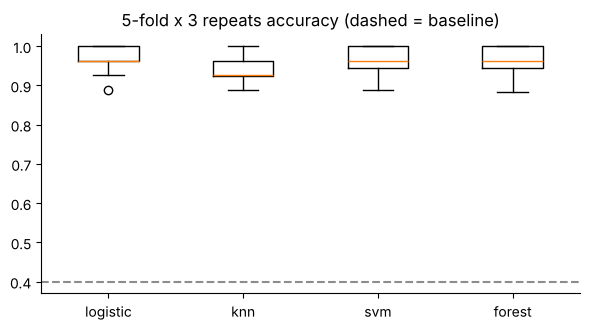

In [3]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RepeatedStratifiedKFold, cross_val_score
candidates = {
    "logistic": make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)),
    "knn": make_pipeline(StandardScaler(), KNeighborsClassifier()),
    "svm": make_pipeline(StandardScaler(), SVC()),
    "forest": RandomForestClassifier(n_estimators=200, random_state=0),
}
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=0)
cv_scores = {n: cross_val_score(m, X_train, y_train, cv=cv) for n, m in candidates.items()}
cv_table = pd.DataFrame({n: {"mean": s.mean(), "std": s.std(), "min": s.min()} for n, s in cv_scores.items()}).T.round(3)
print(cv_table.sort_values("mean", ascending=False).to_string())
fig, ax = plt.subplots(figsize=(6, 3.4))
ax.boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
ax.axhline(base_acc, ls="--", color=GRAY); ax.set_title("5-fold x 3 repeats accuracy (dashed = baseline)")
plt.tight_layout(); plt.show()

**Giải thích từng dòng**

- `make_pipeline(StandardScaler(), ...)`: chuẩn hóa nằm **trong** pipeline nên mỗi lần chia chỉ học thang đo từ phần học (không rò rỉ, D1).
- `RepeatedStratifiedKFold(5, 3)`: kiểm chứng chéo 5 phần lặp 3 lần: 15 điểm số mỗi mô hình, ước lượng ổn định hơn một lần chia.
- `cross_val_score(m, X_train, y_train, cv=cv)`: điểm số trên phần giữ lại của từng lần chia. Chỉ dùng **tập học**; tập thi vẫn cất.
- `mean, std, min`: trung bình, độ phân tán, và lần tệ nhất: cho biết cả mức và độ ổn định.

**Cách đọc.**
- **Con số:** điểm trung bình: logistic 0,968 (std 0,030), svm 0,967 (std 0,036), forest 0,962 (std 0,039), knn 0,945 (std 0,030).
- **Bức tranh:** với dữ liệu sạch như thế này, nhiều mô hình đạt gần nhau; chênh lệch nhỏ hơn hoặc bằng độ phân tán thì **không đủ cơ sở** để nói cái nào hơn. Khi hòa, ưu tiên cái **đơn giản và dễ giải thích** (hồi quy logistic có hệ số đọc được).
- **Quy tắc đọc:** so sánh phải trên cùng cách chia (ở đây dùng chung `cv`); đừng chọn theo tập thi.

**Mang về chặng 2:** chọn theo kiểm chứng chéo trên tập học; hòa thì chọn mô hình đơn giản.

## Chặng 2: Tinh chỉnh và thi một lần

**Câu hỏi:** chỉnh siêu tham số của mô hình được chọn, rồi báo cáo trên tập thi **một lần duy nhất**.

In [4]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import accuracy_score, confusion_matrix
pipe = make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000))
grid = GridSearchCV(pipe, {"logisticregression__C": [0.01, 0.1, 1, 10, 100]}, cv=cv, scoring="accuracy").fit(X_train, y_train)
print("best C:", grid.best_params_["logisticregression__C"], "| CV accuracy at best:", round(grid.best_score_, 3))
print(pd.Series(grid.cv_results_["mean_test_score"], index=[0.01, 0.1, 1, 10, 100]).round(3).to_string())
final = grid.best_estimator_
pred = final.predict(X_test)
test_acc = accuracy_score(y_test, pred)
from scipy.stats import binomtest
hits = (pred == y_test.to_numpy())
ci_obj = binomtest(int(hits.sum()), len(hits)).proportion_ci(confidence_level=0.95, method="exact")
lo, hi = ci_obj.low, ci_obj.high
print("TEST accuracy:", round(test_acc, 3), "| 95% CI:", round(float(lo), 3), "to", round(float(hi), 3), "| n =", len(hits))
print(confusion_matrix(y_test, pred))

best C: 0.1 | CV accuracy at best: 0.975
0.01      0.970
0.10      0.975
1.00      0.968
10.00     0.958
100.00    0.955
TEST accuracy: 1.0 | 95% CI: 0.921 to 1.0 | n = 45
[[15  0  0]
 [ 0 18  0]
 [ 0  0 12]]


**Giải thích từng dòng**

- `GridSearchCV(pipe, {"logisticregression__C": [...]})`: thử 5 giá trị của `C` (độ mạnh điều chuẩn, B3) bằng kiểm chứng chéo, **chỉ trên tập học**.
- `grid.best_estimator_`: mô hình tốt nhất đã học lại trên toàn bộ tập học.
- `accuracy_score(y_test, final.predict(X_test))`: chạm tập thi **đúng một lần**, sau khi mọi lựa chọn đã chốt.
- `binomtest(...).proportion_ci(method="exact")`: khoảng tin cậy **chính xác** (Clopper-Pearson) cho tỷ lệ đúng. Không dùng bootstrap ở đây: khi đúng hết 100% mẫu, mọi lần rút lại đều ra 100% nên bootstrap báo khoảng "1 đến 1", sai lệch hoàn toàn.
- `confusion_matrix`: ma trận nhầm lẫn: giống nào hay bị nhầm với giống nào.

**Cách đọc.**
- **Con số:** `C` tốt nhất là **0.1**, kiểm chứng chéo 0,975. Trên tập thi: độ chính xác **1,000**, khoảng tin cậy 95% từ **0,921** đến **1,000** trên chỉ 45 mẫu; số mẫu bị nhầm: **0**.
- **Bức tranh:** tập thi chỉ có 45 mẫu nên mỗi mẫu sai làm độ chính xác đổi khoảng 2,2 điểm phần trăm; khoảng tin cậy phản ánh đúng điều đó. Đúng hết 45 mẫu **không** có nghĩa mô hình đúng 100% ngoài đời: cận dưới của khoảng tin cậy chính xác chỉ cỡ 0,921. Báo "đạt 100%" mà không kèm khoảng là thiếu trung thực.
- **Quy tắc đọc:** nếu thấy điểm thi quá đẹp, kiểm lại rò rỉ trước khi ăn mừng (D1); ở đây chuẩn hóa nằm trong pipeline và tập thi chỉ chạm một lần.

**Mang về chặng 3:** thi một lần, báo cả khoảng tin cậy.

## Chặng 3: Lưu, hàm dự đoán, thẻ mô hình

**Câu hỏi:** giao mô hình thế nào để người khác dùng được và không vỡ?

In [5]:
import os, joblib, json, tempfile, sklearn
workdir = tempfile.mkdtemp()
joblib.dump(final, os.path.join(workdir, "wine_model.joblib"))
golden = X_test.head(5)
meta = {"name": "wine_cultivar_v1", "sklearn_version": sklearn.__version__, "input_columns": list(X.columns),
        "ranges": {c: [float(X_train[c].min()), float(X_train[c].max())] for c in X.columns},
        "test_accuracy": round(float(test_acc), 3), "golden_proba": final.predict_proba(golden).round(6).tolist()}
json.dump(meta, open(os.path.join(workdir, "meta.json"), "w"))
loaded = joblib.load(os.path.join(workdir, "wine_model.joblib"))
meta_in = json.load(open(os.path.join(workdir, "meta.json")))
def predict_wine(row):
    missing = [c for c in meta_in["input_columns"] if c not in row or row[c] is None]
    if missing:
        return {"status": "refused", "errors": [f"{c}: missing" for c in missing]}
    outside = [c for c in meta_in["input_columns"] if not meta_in["ranges"][c][0] <= row[c] <= meta_in["ranges"][c][1]]
    frame = pd.DataFrame([row])[meta_in["input_columns"]]
    proba = loaded.predict_proba(frame)[0]
    k = int(proba.argmax())
    return {"status": "ok", "class": str(wine.target_names[k]), "probability": round(float(proba[k]), 3), "warnings": [f"{c}: outside training range" for c in outside]}
good = predict_wine(X_test.iloc[0].to_dict())
odd = predict_wine({**X_test.iloc[0].to_dict(), "alcohol": 40.0})
bad = predict_wine({k: v for k, v in X_test.iloc[0].to_dict().items() if k != "ash"})
golden_ok = bool(np.allclose(loaded.predict_proba(golden), np.array(meta_in["golden_proba"]), atol=1e-5))
print("golden check:", golden_ok)
print(good); print(odd); print(bad)
print("true label of that row:", wine.target_names[y_test.iloc[0]])

golden check: True
{'status': 'ok', 'class': 'class_2', 'probability': 0.953, 'warnings': []}
{'status': 'ok', 'class': 'class_0', 'probability': 0.997, 'warnings': ['alcohol: outside training range']}
{'status': 'refused', 'errors': ['ash: missing']}
true label of that row: class_2


**Giải thích từng dòng**

- `joblib.dump(final, ...)`: lưu **cả pipeline** (chuẩn hóa + mô hình), như H1.
- `meta = {...}`: siêu dữ liệu: phiên bản thư viện, tên cột, khoảng giá trị đã học, điểm thi, và vài dòng mẫu kèm xác suất kỳ vọng (golden).
- `predict_wine(row)`: hàm dự đoán an toàn (H2): thiếu cột thì từ chối, ngoài khoảng đã học thì cảnh báo, trả lớp và xác suất.
- `np.allclose(..., atol=1e-5)`: kiểm golden: sau khi nạp lại, mô hình phải cho đúng xác suất đã ghi.

**Cách đọc.**
- **Con số:** golden check **True**. Dòng đầu của tập thi: dự đoán **class_2** (xác suất 0,953), nhãn thật class_2. Khi `alcohol = 40`: trạng thái "ok" kèm cảnh báo ['alcohol: outside training range']. Khi thiếu `ash`: trạng thái "refused". Lưu ý: với `alcohol = 40` mô hình vẫn tự tin đến 0,997, đúng kiểu "tự tin vô lý" ngoài vùng đã học, nên cảnh báo của hàm dự đoán là bắt buộc.
- **Bức tranh:** ba phần của việc giao: **tệp mô hình + siêu dữ liệu**, **hàm dự đoán biết từ chối và cảnh báo**, **kiểm golden** khi nạp. Thêm thẻ mô hình (H4) với khoảng tin cậy ở chặng 2, và kế hoạch giám sát (H3) khi có dữ liệu mới.
- **Lưu ý:** tập thi có 45 mẫu nên mức hiệu quả có sai số đáng kể; thẻ mô hình phải ghi rõ điều đó.

**Mang về:** một dự án hoàn chỉnh là chuỗi: mốc chuẩn, so sánh có kiểm chứng, thi một lần, lưu cẩn thận, hàm dự đoán an toàn, báo cáo trung thực.

## Chặng 4: Bài tập tự làm trên dữ liệu ung thư vú

**Hiện trường.** Một bệnh viện muốn công cụ **hỗ trợ sàng lọc** từ số đo khối u (`load_breast_cancer`): mô hình báo mẫu nào nên được chuyên gia xem lại. Ở đây **bỏ sót ca ác tính nguy hiểm hơn báo nhầm**, nên ta quan tâm cả *recall* của lớp ác tính, không chỉ độ chính xác. Dữ liệu này chỉ để học kỹ thuật, không phải công cụ y khoa.

Dưới đây là khung bài với các ô trống `___`. Chép vào ô code mới, điền, chạy, rồi so với lời giải ở chặng 5. Gợi ý nằm trong chú thích.

```python
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import recall_score, accuracy_score

data = load_breast_cancer(as_frame=True)
X, y = data.data, data.target          # y: 0 = malignant, 1 = benign

# 1. Chia dữ liệu, giữ tỷ lệ lớp, cất tập thi
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=___, random_state=0, stratify=___)

# 2. Pipeline gồm chuẩn hóa rồi hồi quy logistic
pipe = make_pipeline(___(), LogisticRegression(max_iter=5000))

# 3. Tinh chỉnh C bằng kiểm chứng chéo CHỈ trên tập học
grid = GridSearchCV(pipe, {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="___").fit(X_train, ___)

# 4. Thi một lần; tính recall của lớp ÁC TÍNH (nhãn 0)
pred = grid.best_estimator_.predict(___)
recall_malignant = recall_score(y_test, pred, pos_label=___)
print(accuracy_score(y_test, pred), recall_malignant)
```

**Câu hỏi tư duy sau khi chạy:**
1. Độ chính xác và recall của lớp ác tính chênh nhau bao nhiêu? Vì sao "chính xác 97%" chưa đủ trả lời?
2. Hạ ngưỡng xác suất của lớp ác tính từ 0,5 xuống thấp hơn: recall và số báo nhầm đổi thế nào?
3. Viết ba dòng cho mục "Giới hạn" của thẻ mô hình.

## Chặng 5: Lời giải và đối chiếu

**Câu hỏi:** lời giải điền sẵn cho ra kết quả gì, và ngưỡng thấp hơn đổi được gì?

In [6]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import cross_val_score
from sklearn.metrics import recall_score, precision_score
data = load_breast_cancer(as_frame=True)
Xc, yc = data.data, data.target
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size=0.25, random_state=0, stratify=yc)
pipe_c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
grid_c = GridSearchCV(pipe_c, {"logisticregression__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="recall").fit(Xc_train, 1 - yc_train)
print("best C by recall of the malignant class (relabelled as 1):", grid_c.best_params_["logisticregression__C"], "| CV recall:", round(grid_c.best_score_, 3))
model_c = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, C=grid_c.best_params_["logisticregression__C"])).fit(Xc_train, yc_train)
p_malignant = model_c.predict_proba(Xc_test)[:, 0]
y_mal = (yc_test == 0).to_numpy()
rows = []
for t in (0.5, 0.3, 0.1):
    flag = p_malignant >= t
    rows.append({"threshold": t, "flagged": int(flag.sum()), "recall_malignant": recall_score(y_mal, flag), "precision": precision_score(y_mal, flag), "missed": int((y_mal & ~flag).sum()), "false_alarms": int((~y_mal & flag).sum())})
thr = pd.DataFrame(rows).round(3).set_index("threshold")
print("test accuracy at 0.5:", round(float(accuracy_score(yc_test, model_c.predict(Xc_test))), 3), "| malignant in test:", int(y_mal.sum()), "of", len(y_mal))
print(thr.to_string())

best C by recall of the malignant class (relabelled as 1): 0.1 | CV recall: 0.95
test accuracy at 0.5: 0.958 | malignant in test: 53 of 143
           flagged  recall_malignant  precision  missed  false_alarms
threshold                                                            
0.5             49             0.906      0.980       5             1
0.3             57             0.962      0.895       2             6
0.1             71             1.000      0.746       0            18


**Giải thích từng dòng**

- `scoring="recall"`: chọn `C` theo recall; vì nhãn gốc 0 là ác tính, ta đảo nhãn (`1 - y`) để ác tính thành lớp dương cho `recall`.
- `p_malignant = ...predict_proba(Xc_test)[:, 0]`: cột 0 của `predict_proba` là xác suất lớp nhãn 0, tức **ác tính**.
- `flag = p_malignant >= t`: gắn cờ "cần xem lại" khi xác suất ác tính từ ngưỡng `t` trở lên.
- `missed, false_alarms`: bỏ sót (ác tính mà không gắn cờ) và báo nhầm (lành mà gắn cờ): đánh đổi cốt lõi của ngưỡng.

**Cách đọc.**
- **Con số:** ở ngưỡng 0,5 mô hình đạt độ chính xác 0,958 trên 143 mẫu thi (53 ác tính): bỏ sót **5**, báo nhầm **1**. Ở ngưỡng 0,3: bỏ sót **2**, báo nhầm **6**. Ở ngưỡng 0,1: bỏ sót **0**, báo nhầm **18**.
- **Bức tranh:** hạ ngưỡng thì số ca bỏ sót giảm (hoặc giữ nguyên) và số báo nhầm tăng: đúng đánh đổi mong đợi. Với tập thi chỉ vài chục ca ác tính, mỗi ca đổi recall nhiều điểm phần trăm, nên đừng đọc quá kỹ từng con số mà hãy đọc **xu hướng**.
- **Quy tắc đọc:** trong bài toán mà hai loại sai có giá khác nhau, ngưỡng chọn theo **chi phí** (H2, chặng 4), và báo cáo dùng recall, precision kèm khoảng tin cậy (H4).

**Mang về:** làm lại được quy trình trên dữ liệu khác, và chọn ngưỡng theo hậu quả của từng loại sai.

## Tổng kết

**Mang về theo từng chặng**

| Chặng | Mang về |
|---|---|
| 0 | Chia tập thi trước, có mốc chuẩn. |
| 1 | So mô hình bằng kiểm chứng chéo lặp trên tập học; hòa thì chọn đơn giản. |
| 2 | Tinh chỉnh trên tập học, thi một lần, kèm khoảng tin cậy. |
| 3 | Giao mô hình: tệp, siêu dữ liệu, golden, hàm dự đoán an toàn. |
| 4 | Bài tập tự làm: khung có ô trống, tự điền và chạy. |
| 5 | Ngưỡng chọn theo hậu quả của từng loại sai, đọc xu hướng chứ không đọc từng ca. |

**Bảng đối chiếu: đời thường, thuật ngữ, tên trong code**

| Đời thường | Thuật ngữ | Tên trong code |
|---|---|---|
| Bữa tiệc từ đầu đến cuối | dự án trọn vẹn | H5 chặng 0 đến 3 |
| Món đối chứng | mốc chuẩn | `DummyClassifier` |
| Nếm thử nhiều lần | kiểm chứng chéo lặp | `RepeatedStratifiedKFold` |
| Chỉ nếm món cuối một lần | thi một lần | `test_acc` |
| Gói hàng kèm phiếu kiểm | tệp, siêu dữ liệu, golden | `joblib`, `meta.json` |
| Thà báo nhầm hơn bỏ sót | chọn ngưỡng theo chi phí | `thr` |

**Thử thách tự làm**

1. Ở chặng 1, thêm `GradientBoostingClassifier` vào `candidates`. Nó có hơn hồi quy logistic ngoài khoảng nhiễu không?
2. Ở chặng 2, thay `accuracy` bằng `f1_macro` trong `GridSearchCV`. `C` tốt nhất có đổi không?
3. Ở chặng 3, thêm kiểm tra phiên bản sklearn khi nạp: khác phiên bản thì cảnh báo (H1).
4. Ở chặng 5, chọn ngưỡng sao cho bỏ sót bằng 0 trên tập học đã cho, rồi báo cáo số báo nhầm trên tập thi. Con số này đáng tin đến đâu?

**Checklist năng lực** (tự tick khi làm được)

- [ ] Chia tập thi và đặt mốc chuẩn trước khi chọn mô hình.
- [ ] So mô hình bằng kiểm chứng chéo lặp trên tập học.
- [ ] Chạm tập thi một lần và báo khoảng tin cậy.
- [ ] Lưu mô hình kèm siêu dữ liệu và kiểm golden.
- [ ] Chọn ngưỡng theo hậu quả của từng loại sai.

## Phần thưởng (Tip pro): Hết khóa: bạn đã đi từ dữ liệu đến sản phẩm


Khóa học dừng ở đây, nhưng quy trình thì tái dùng được: mốc chuẩn, kiểm chứng đúng cách, tinh chỉnh, thi một lần, giao cẩn thận, giám sát, báo cáo trung thực. Hãy thử lại trên một bộ dữ liệu của chính bạn.